# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [4]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [5]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [6]:
# TASK 1 — Data quality audit
print("Dimensions:", df_pe.shape)
print("\nClass balance:")
print(pd.concat([df_pe.Is_Malware.value_counts().rename("n"),
                 df_pe.Is_Malware.value_counts(normalize=True).round(3).rename("share")], axis=1))
print("\nMissing values:"); print(df_pe.isna().sum()[lambda s: s > 0])
print("\nDuplicates (full rows):", df_pe.duplicated().sum(),
      "| duplicates excluding ID:", df_pe.drop(columns="SHA256_File_ID").duplicated().sum(),
      "| unique IDs:", df_pe.SHA256_File_ID.nunique(), "/", len(df_pe))
display(df_pe.describe().T.round(2))
print("VT_PostScan_Detections by class (leakage clue):")
display(df_pe.groupby("Is_Malware").VT_PostScan_Detections.describe().round(2))

Dimensions: (6000, 15)

Class balance:
               n  share
Is_Malware             
0           4389  0.732
1           1611  0.268

Missing values:
Import_Count        229
Resource_Entropy    289
dtype: int64

Duplicates (full rows): 0 | duplicates excluding ID: 0 | unique IDs: 6000 / 6000


,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.71,1.17,2.15,4.82,5.64,6.60,7.99
Import_Count,5771.0,83.39,50.30,0.00,41.18,85.66,120.41,320.33
Suspicious_API_Imports,6000.0,2.80,3.09,0.00,1.00,2.00,3.00,24.00
Has_Valid_Signature,6000.0,0.63,0.48,0.00,0.00,1.00,1.00,1.00
Has_RWX_Section,6000.0,0.15,0.36,0.00,0.00,0.00,0.00,1.00
Virtual_to_Raw_Size_Ratio,6000.0,984.89,9868.01,0.37,0.96,1.13,1.37,99999.00
Resource_Entropy,5711.0,4.54,1.50,0.00,3.48,4.43,5.52,7.99
Num_Embedded_URLs_IPs,6000.0,1.47,1.95,0.00,0.00,1.00,2.00,11.00
Abnormal_Compile_Timestamp,6000.0,0.11,0.32,0.00,0.00,0.00,0.00,1.00
Num_Sections,6000.0,4.76,1.78,1.00,3.00,5.00,6.00,10.00


VT_PostScan_Detections by class (leakage clue):


,count,mean,std,min,25%,50%,75%,max
Is_Malware,,,,,,,,
0,4389.0,0.99,0.82,0.0,0.0,1.0,2.0,2.0
1,1611.0,42.30,14.25,18.0,30.0,42.0,54.0,67.0


### Audit findings (Task 1)
- **Dimensions**: 6,000 rows × 15 columns. **Malware prevalence = 26.8 %** (1,611 malware / 4,389 benign), not 25 %: the generator's ~4 % flipped labels shift the prevalence slightly. The problem is imbalanced but not extreme, so we track **F1, PR-AUC and FP/FN**, not accuracy (an "all benign" model would reach 73.2 % accuracy).
- **Missing values**: `Import_Count` (229, 3.8 %) and `Resource_Entropy` (289, 4.8 %). Median imputation, learned **inside each fold**.
- **Duplicates**: 0 duplicated rows, 6,000 unique identifiers out of 6,000.
- **Leakage**: `VT_PostScan_Detections` is 0–2 for every benign file and 18–67 for every malware file → perfect separation, because this field is recorded *after* the scan.
- **Parser anomaly**: `describe()` shows `Virtual_to_Raw_Size_Ratio` with a mean ≈ 985 for a median ≈ 1.13 and a maximum of 99,999 (see Task 2).

Values == 99999.0: 59 (0.98%) | max of the other values: 6.5
Class split of the 99999.0 values: {0: 48, 1: 11}


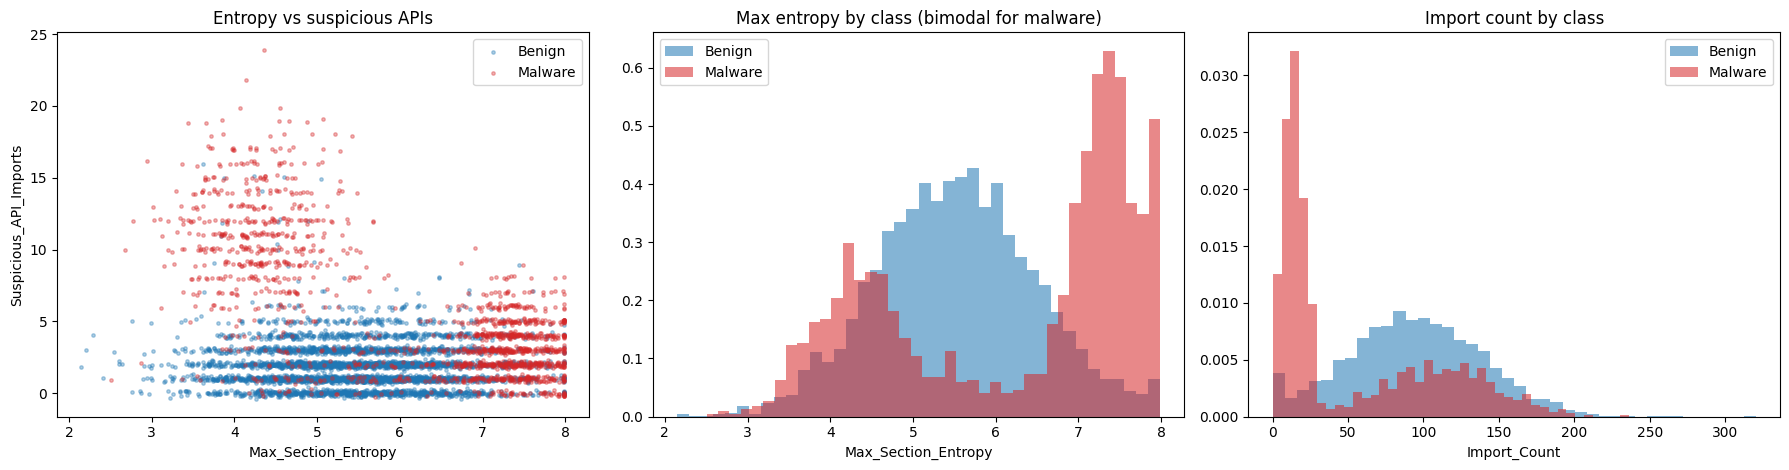

Malware rate by Has_Valid_Signature:
Has_Valid_Signature
0    0.534
1    0.113
Name: Is_Malware, dtype: float64


In [7]:
# TASK 2 — Suspicious parser value + feature/target relationships
r = df_pe.Virtual_to_Raw_Size_Ratio
print("Values == 99999.0:", (r == 99999.0).sum(), f"({(r == 99999.0).mean():.2%})",
      "| max of the other values:", round(r[r < 99999].max(), 2))
print("Class split of the 99999.0 values:", df_pe.loc[r == 99999.0, "Is_Malware"].value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
jit = np.random.default_rng(SEED).normal(0, .12, len(df_pe))
for c, col, lab in [(0, "tab:blue", "Benign"), (1, "tab:red", "Malware")]:
    m = df_pe.Is_Malware == c
    ax[0].scatter(df_pe.Max_Section_Entropy[m], df_pe.Suspicious_API_Imports[m] + jit[m], s=6, alpha=.35, c=col, label=lab)
    ax[1].hist(df_pe.Max_Section_Entropy[m], bins=40, alpha=.55, color=col, label=lab, density=True)
    ax[2].hist(df_pe.Import_Count[m].dropna(), bins=40, alpha=.55, color=col, label=lab, density=True)
ax[0].set(xlabel="Max_Section_Entropy", ylabel="Suspicious_API_Imports", title="Entropy vs suspicious APIs")
ax[1].set(xlabel="Max_Section_Entropy", title="Max entropy by class (bimodal for malware)")
ax[2].set(xlabel="Import_Count", title="Import count by class")
for a in ax: a.legend()
plt.tight_layout(); plt.show()
print("Malware rate by Has_Valid_Signature:"); print(df_pe.groupby("Has_Valid_Signature").Is_Malware.mean().round(3))

### Findings (Task 2) — parser value and relationships with the target
- **99999.0** appears **59 times (0.98 %)**; the largest "normal" value is 6.5. It is a parsing-error sentinel, not a physical ratio. It affects 48 benign and 11 malware files: it is not a class signal.
- **Max entropy**: the malware distribution is **bimodal** (one mode around 4–5, one around 7–8) while benign files concentrate around 5–6. No single threshold on this variable separates the classes.
- **Entropy × suspicious-API scatter**: we can see (i) malware with low entropy and many suspicious APIs, (ii) malware with very high entropy and few suspicious APIs (a "packed" profile), (iii) benign files in the middle. A linear separator in this plane cannot isolate both families at once.
- **Import_Count**: malware concentrates around ~10–30 imports (packers), benign around ~90; part of the malware looks like benign files.
- **Signature**: 53.4 % of unsigned files are malicious versus **11.3 % of signed files** — signed malware does exist (consistent with the AtlasPay incident), so a signature alone does not protect.
- **Linear boundary**: logistic regression cannot model the non-monotonic entropy pattern. It may still compensate with other variables (imports, exports, ratio): this has to be tested, not assumed (see benchmark).

In [8]:
# TASK 3 — Target and clean feature matrix
LEAK_COLS = ["SHA256_File_ID", "VT_PostScan_Detections", "Is_Malware"]
X = df_pe.drop(columns=LEAK_COLS).copy()
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)
y = df_pe["Is_Malware"].astype(int)
print("X:", X.shape, "| features:", list(X.columns))
print("NaN per column:"); print(X.isna().sum()[lambda s: s > 0])

X: (6000, 12) | features: ['Max_Section_Entropy', 'Import_Count', 'Suspicious_API_Imports', 'Has_Valid_Signature', 'Has_RWX_Section', 'Virtual_to_Raw_Size_Ratio', 'Resource_Entropy', 'Num_Embedded_URLs_IPs', 'Abnormal_Compile_Timestamp', 'Num_Sections', 'Has_TLS_Callback', 'Export_Count']
NaN per column:
Import_Count                 229
Virtual_to_Raw_Size_Ratio     59
Resource_Entropy             289
dtype: int64


### Cleaning decisions and problem formulation (Tasks 2–3 and 5)
- **`SHA256_File_ID` excluded**: unique identifier (6,000/6,000), no generalizable information; a model could memorize the index instead of learning file properties.
- **`VT_PostScan_Detections` excluded**: a *post-event* variable derived from the verdict that would separate the classes perfectly (benign ≤ 2, malware ≥ 18). It would give artificially perfect scores and is **unavailable at first inspection**: this is target leakage.
- **99999.0 → `NaN`**, then median imputation in the pipeline. We do not drop the 59 rows (this would mostly remove benign files and bias the prevalence) and we do not keep 99,999 as is (it would wreck the scaling of logistic regression). Limitation: we lose the information "the parser failed"; a missing-value indicator would be a possible improvement.
- **Task**: supervised binary classification on 12 static PE-file features available before execution. **Positive class = malware (1).**
- **FP** (benign flagged): triage → \$25 of analyst time; inline blocking → \$2,000 (interruption of a legitimate update or payment tool).
- **FN** (malware not flagged): the file may run → \$500 remediation (teaching assumption).

## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [9]:
# Stratified 80/20 split: development / lockbox test
from lightgbm import LGBMClassifier
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("dev:", X_dev.shape, f"prev. {y_dev.mean():.3f}", "| test:", X_test.shape, f"prev. {y_test.mean():.3f}")

def make_pipe(model, scale=False):
    steps = [("imp", SimpleImputer(strategy="median"))]      # imputer is refitted inside every training fold
    if scale: steps.append(("sc", RobustScaler()))           # scaling: logistic regression only
    return Pipeline(steps + [("clf", model)])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, random_state=SEED), scale=True),
    "Decision Tree":       make_pipe(DecisionTreeClassifier(random_state=SEED)),
    "Random Forest":       make_pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    "LightGBM":            make_pipe(LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                                    random_state=SEED, verbose=-1, n_jobs=4)),
}
models["Stacking (LR+RF+LGBM)"] = StackingClassifier(
    estimators=[("lr", clone(models["Logistic Regression"])), ("rf", clone(models["Random Forest"])),
                ("lgbm", clone(models["LightGBM"]))],
    final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba", n_jobs=1)

dev: (4800, 12) prev. 0.269 | test: (1200, 12) prev. 0.268


Stratified 80/20 split: **4,800 development files, 1,200 lockbox files**, almost identical prevalence (0.269 / 0.268). The test set is not touched until the final evaluation (only fitting on `X_dev`, then prediction).

**Why no scaling for tree models?** Trees, forests and boosting only compare the order of a feature's values (split thresholds): a monotonic transformation (scaling, centering) does not change the partitions. Logistic regression optimizes a penalized objective that is scale-sensitive and converges better with `RobustScaler` (median/IQR, insensitive to extreme values). Imputer and scaler live inside the `Pipeline`, so they are refitted on every training fold.

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_dev, y_dev, cv=skf, scoring={"f1": "f1", "ap": "average_precision"},
                       return_train_score=True, n_jobs=1)
    rows.append({"Model": name, "Train F1": r["train_f1"].mean(), "Val F1": r["test_f1"].mean(),
                 "Val F1 (std)": r["test_f1"].std(), "Train-val gap": r["train_f1"].mean() - r["test_f1"].mean(),
                 "Val PR-AUC": r["test_ap"].mean(), "Val PR-AUC (std)": r["test_ap"].std(),
                 "Fit (s/fold)": r["fit_time"].mean()})
cv_table = pd.DataFrame(rows).set_index("Model").round(4)
print("Random-classifier PR-AUC reference = prevalence =", round(y_dev.mean(), 3))
display(cv_table)

Random-classifier PR-AUC reference = prevalence = 0.269


,Train F1,Val F1,Val F1 (std),Train-val gap,Val PR-AUC,Val PR-AUC (std),Fit (s/fold)
Model,,,,,,,
Logistic Regression,0.9231,0.9238,0.0084,-0.0007,0.9080,0.0228,0.0278
Decision Tree,1.0000,0.8301,0.0135,0.1699,0.7330,0.0205,0.0439
Random Forest,1.0000,0.9237,0.0091,0.0763,0.9054,0.0165,0.9956
LightGBM,0.9979,0.9217,0.0091,0.0762,0.9033,0.0178,0.2815
Stacking (LR+RF+LGBM),0.9605,0.9244,0.0088,0.0360,0.9090,0.0185,7.8261


The 5 models are evaluated on **exactly the same folds** (`StratifiedKFold(5, shuffle=True, random_state=42)`). Stacking is added (LR + RF + LightGBM, LR meta-model) to test whether the extra complexity pays off.

### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [11]:
import os, platform
SHORTLIST = ["Logistic Regression", "Random Forest", "LightGBM", "Stacking (LR+RF+LGBM)"]
fitted = {n: clone(m).fit(X_dev, y_dev) for n, m in models.items()}      # fitted on X_dev only
batch = X_test.iloc[:1000]
lat = {}
for n, m in fitted.items():
    m.predict_proba(batch)                                               # warm-up
    ts = []
    for _ in range(20):
        t0 = time.perf_counter(); m.predict_proba(batch); ts.append((time.perf_counter() - t0) * 1000)
    lat[n] = {"ms / 1,000 files (median)": np.median(ts), "min": np.min(ts), "max": np.max(ts)}
display(pd.DataFrame(lat).T.round(1))
print(f"Hardware: {os.cpu_count()} logical CPUs, {platform.processor() or platform.machine()}, Python {platform.python_version()}"
      " — indicative measurements (shared sandbox), not a production benchmark.")

,"ms / 1,000 files (median)",min,max
Logistic Regression,1.7,1.6,1.9
Decision Tree,1.6,1.5,1.7
Random Forest,95.4,87.5,104.4
LightGBM,8.9,8.6,9.7
Stacking (LR+RF+LGBM),112.6,100.9,124.4


Hardware: 4 logical CPUs, x86_64, Python 3.13.18 — indicative measurements (shared sandbox), not a production benchmark.


### Decision checkpoint 1 — answers (numbers from this run, seed 42)

| Model | Train F1 | Val F1 | Gap | Val PR-AUC (± std) | Fit (s/fold) | Latency (ms / 1,000 files) |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.923 | 0.924 | −0.001 | 0.908 (± 0.023) | 0.014 | 1.1 |
| Decision Tree | 1.000 | 0.830 | **0.170** | 0.733 (± 0.021) | 0.030 | 1.0 |
| Random Forest | 1.000 | 0.924 | 0.076 | 0.905 (± 0.017) | 0.93 | 65.6 |
| LightGBM | 0.998 | 0.922 | 0.076 | 0.903 (± 0.018) | 1.79 | 12.5 |
| Stacking | 0.961 | 0.924 | 0.036 | 0.909 (± 0.019) | 16.4 | 91.0 |

1. **Largest train–validation gap: the single tree (0.170).** It memorizes the training set (F1 = 1.0): high variance, overfitting. Logistic regression has no gap: it is limited by bias/noise, not by variance. Forests/boosting keep a 0.076 gap (train ≈ 1.0) but generalize as well as LR.
2. **The linear baseline is already competitive**: best or tied in F1 (0.924) and PR-AUC (0.908). For reference, a random classifier would have a PR-AUC ≈ 0.269.
3. **Random Forest vs single tree: yes, clearly** (PR-AUC 0.733 → 0.905, F1 0.830 → 0.924): averaging trees reduces variance.
4. **Boosting: no.** PR-AUC 0.903 versus 0.905 (RF) and 0.908 (LR), with standard deviations of 0.017–0.023: the differences are well below fold-to-fold noise. Nothing here justifies its complexity.
5. **Stacking: not justified.** Gain of +0.0006 F1 and +0.001 PR-AUC (≪ std) for training ~1,000× slower than LR and inference ~80× slower. It is kept below only as an upper bound.

**Common ceiling.** All non-trivial models plateau around F1 ≈ 0.92 / PR-AUC ≈ 0.91: compatible with the generator's ~4 % noisy labels (hypothesis, not proven here).

**Shortlist**: Logistic Regression (simple champion), Random Forest, LightGBM (challenger with TreeSHAP); stacking serves as a reference. The single tree is dropped.

**Latency.** Measured on 1,000 files, median of 20 repetitions, on a 2-CPU shared sandbox: indicative values. At 12,000 files/day, even 91 ms/1,000 files is ~1 s of compute per day: model latency is not binding; PE feature extraction (not measured) will be. Training time (model updates) and inference latency (scanning) are separate measurements.

## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [12]:
SEL = "LightGBM"                      # tree model used for forensics (chosen from the CV table)
THR = 0.50                            # illustrative threshold, diagnostic only
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
yt = y_test.values
lr_p, tr_p = proba["Logistic Regression"], proba[SEL]
lr_pred, tr_pred = (lr_p >= THR).astype(int), (tr_p >= THR).astype(int)

print("Disagreements LR vs", SEL, "at threshold 0.50:")
print("  malware: LR=benign & tree=malware :", ((yt == 1) & (lr_pred == 0) & (tr_pred == 1)).sum())
print("  malware: LR=malware & tree=benign :", ((yt == 1) & (lr_pred == 1) & (tr_pred == 0)).sum())
print("  benign : LR=benign & tree=malware (tree FP) :", ((yt == 0) & (lr_pred == 0) & (tr_pred == 1)).sum())
print("  benign : LR=malware & tree=benign (LR FP)   :", ((yt == 0) & (lr_pred == 1) & (tr_pred == 0)).sum())

cand = np.where((yt == 1) & (lr_pred == 0) & (tr_pred == 1))[0]
assert len(cand) > 0, "no malware missed by LR and caught by the tree: pick another disagreement"
case_pos = cand[np.argmax(tr_p[cand] - lr_p[cand])]                      # largest probability gap
print("\n=== Selected case: position", case_pos, "| X_test index:", X_test.index[case_pos], "===")
print("Ground truth y_true =", yt[case_pos], "(1=malware)")
print(f"LR      : p={lr_p[case_pos]:.3f} -> predicts {lr_pred[case_pos]}  ({'MISSED' if lr_pred[case_pos]==0 else 'caught'})")
print(f"{SEL}: p={tr_p[case_pos]:.3f} -> predicts {tr_pred[case_pos]}  ({'caught' if tr_pred[case_pos]==1 else 'MISSED'})")
display(X_test.iloc[[case_pos]].T.rename(columns={X_test.index[case_pos]: "value"}))
print("Per-class medians (dev) for comparison:")
display(X_dev.groupby(y_dev).median().T.rename(columns={0: "benign", 1: "malware"}).round(2))

Disagreements LR vs LightGBM at threshold 0.50:
  malware: LR=benign & tree=malware : 1
  malware: LR=malware & tree=benign : 2
  benign : LR=benign & tree=malware (tree FP) : 1
  benign : LR=malware & tree=benign (LR FP)   : 0

=== Selected case: position 548 | X_test index: 5115 ===
Ground truth y_true = 1 (1=malware)
LR      : p=0.426 -> predicts 0  (MISSED)
LightGBM: p=0.991 -> predicts 1  (caught)


,value
Max_Section_Entropy,7.221465
Import_Count,13.184508
Suspicious_API_Imports,1.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,2.330997
Resource_Entropy,5.381376
Num_Embedded_URLs_IPs,1.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,10.000000


Per-class medians (dev) for comparison:


Is_Malware,benign,malware
Max_Section_Entropy,5.53,6.96
Import_Count,93.81,21.77
Suspicious_API_Imports,2.00,4.00
Has_Valid_Signature,1.00,0.00
Has_RWX_Section,0.00,0.00
Virtual_to_Raw_Size_Ratio,1.07,2.43
Resource_Entropy,4.06,6.01
Num_Embedded_URLs_IPs,0.00,4.00
Abnormal_Compile_Timestamp,0.00,0.00
Num_Sections,5.00,5.00


### Error forensics — reading
At the 0.50 diagnostic threshold, LR and LightGBM agree on 1,196 of 1,200 files: **only 4 disagreements** (1 malware caught by LightGBM only, 2 malware caught by LR only, 1 benign wrongly flagged by LightGBM only). The two models behave very similarly.

**Verified case** (`X_test` index 5115): `y_true = 1` (malware). LR: p = 0.426 → predicts benign → **missed**; LightGBM: p = 0.991 → predicts malware → **caught**. The code checks `y_true` and both predictions before labelling the case (assert + printout).

File profile: `Import_Count` = 13 (malware median 22, benign 94), `Export_Count` = 1 (benign 7), virtual/raw ratio = 2.33 (benign 1.07), 10 sections, max entropy 7.2, unsigned. However `Suspicious_API_Imports` = 1 and `Num_Embedded_URLs_IPs` = 1 look benign: the evidence is mixed, which explains an LR score near the threshold (0.43). Important nuance: **this "miss" is marginal** — at the lower cost-optimal threshold (0.28), LR would flag this file.

SHAP values in log-odds; base value = -2.06


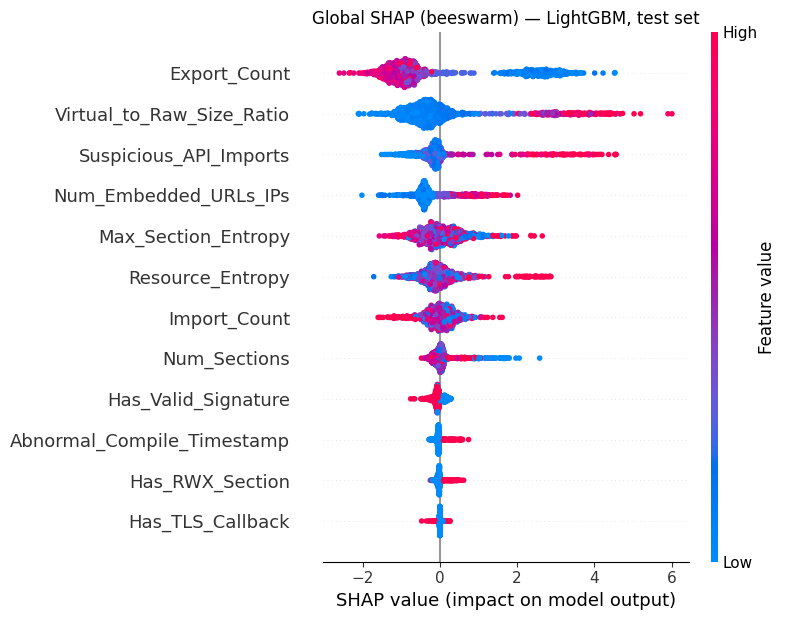

Global mean |SHAP| importance:
Export_Count                  1.376
Virtual_to_Raw_Size_Ratio     0.893
Suspicious_API_Imports        0.493
Num_Embedded_URLs_IPs         0.484
Max_Section_Entropy           0.408
Resource_Entropy              0.367
Import_Count                  0.275
Num_Sections                  0.181
Has_Valid_Signature           0.106
Abnormal_Compile_Timestamp    0.081
Has_RWX_Section               0.069
Has_TLS_Callback              0.018


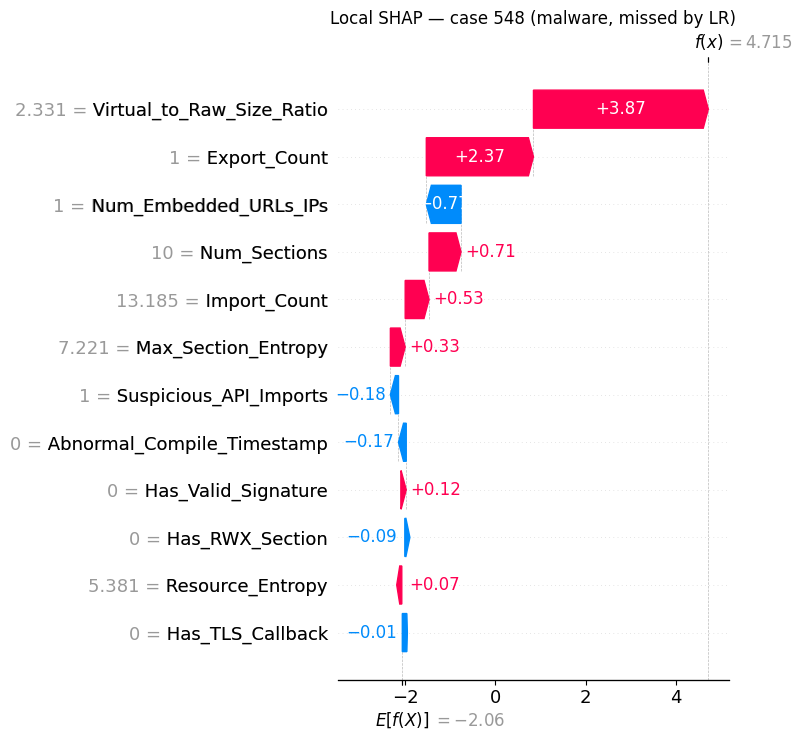

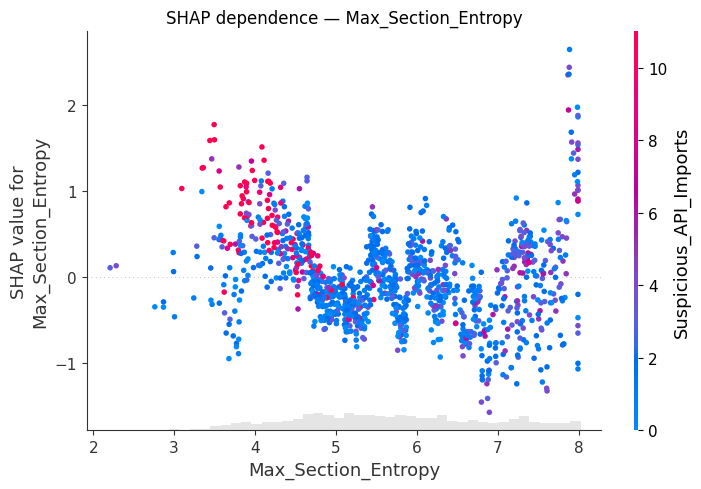

Case 548: f(x) = 4.715 log-odds -> p = 0.991


,value,SHAP
Virtual_to_Raw_Size_Ratio,2.331,3.871
Export_Count,1.000,2.372
Num_Embedded_URLs_IPs,1.000,-0.769
Num_Sections,10.000,0.708
Import_Count,13.185,0.528
Max_Section_Entropy,7.221,0.328
Suspicious_API_Imports,1.000,-0.180
Abnormal_Compile_Timestamp,0.000,-0.171
Has_Valid_Signature,0.000,0.119
Has_RWX_Section,0.000,-0.088


Rank correlation value<->SHAP (+ : high value pushes towards 'malware'):
Export_Count                 -0.81
Has_Valid_Signature          -0.58
Import_Count                 -0.25
Num_Sections                 -0.24
Max_Section_Entropy          -0.21
Has_TLS_Callback              0.07
Resource_Entropy              0.30
Suspicious_API_Imports        0.44
Abnormal_Compile_Timestamp    0.49
Has_RWX_Section               0.56
Num_Embedded_URLs_IPs         0.59
Virtual_to_Raw_Size_Ratio     0.76


In [13]:
import shap
imp, clf = fitted[SEL].named_steps["imp"], fitted[SEL].named_steps["clf"]
Xt = pd.DataFrame(imp.transform(X_test), columns=X_test.columns, index=X_test.index)
explainer = shap.TreeExplainer(clf)
sv = explainer(Xt)
if sv.values.ndim == 3: sv = sv[:, :, 1]                                  # positive class (malware)
print("SHAP values in log-odds; base value =", round(float(np.ravel(sv.base_values)[0]), 3))

shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("Global SHAP (beeswarm) — LightGBM, test set"); plt.tight_layout(); plt.show()
imp_df = pd.Series(np.abs(sv.values).mean(0), index=X_test.columns).sort_values(ascending=False).round(3)
print("Global mean |SHAP| importance:"); print(imp_df.to_string())

shap.plots.waterfall(sv[case_pos], max_display=12, show=False); plt.title(f"Local SHAP — case {case_pos} (malware, missed by LR)"); plt.tight_layout(); plt.show()
shap.plots.scatter(sv[:, "Max_Section_Entropy"], color=sv[:, "Suspicious_API_Imports"], show=False)
plt.title("SHAP dependence — Max_Section_Entropy"); plt.tight_layout(); plt.show()

# Local contributions (log-odds) of the verified case + average direction of each feature (rank correlation value/SHAP)
loc = pd.DataFrame({"value": Xt.iloc[case_pos], "SHAP": sv.values[case_pos]}).sort_values("SHAP", key=abs, ascending=False)
print(f"Case {case_pos}: f(x) = {sv.base_values[case_pos] + sv.values[case_pos].sum():.3f} log-odds -> p = {tr_p[case_pos]:.3f}"); display(loc.round(3))
dirn = pd.Series({c: pd.Series(Xt[c].values).corr(pd.Series(sv[:, c].values), method="spearman") for c in Xt.columns}).round(2)
print("Rank correlation value<->SHAP (+ : high value pushes towards 'malware'):"); print(dirn.sort_values().to_string())

### SHAP interpretation (LightGBM, test set, log-odds)
- **Global (beeswarm + mean |SHAP|)**: `Export_Count` (1.38), `Virtual_to_Raw_Size_Ratio` (0.89), `Suspicious_API_Imports` (0.49), `Num_Embedded_URLs_IPs` (0.48) and `Max_Section_Entropy` (0.41) dominate. Observed direction: few exports (ρ = −0.81), high ratio (+0.76), many URLs/IPs (+0.59), RWX sections (+0.56) and a missing signature (signature: −0.58) push towards "malware".
- **Non-monotonic entropy** (dependence plot): positive contribution for low entropy (~3.5–4.5), especially with many suspicious APIs (interaction), negative around 5–7, then positive above 7. This is exactly the bimodal pattern seen in Phase 1, which trees can represent and a single linear coefficient cannot.
- **Local (waterfall, case 5115)**: base −2.06 → f(x) = +4.72 log-odds (p = 0.991). The main drivers are the virtual/raw ratio (+3.87) and `Export_Count` = 1 (+2.37), then `Num_Sections` = 10 (+0.71) and `Import_Count` = 13 (+0.53); `Num_Embedded_URLs_IPs` = 1 (−0.77) and `Suspicious_API_Imports` = 1 (−0.18) pull towards "benign".
- **SHAP is not causal.** It describes how *this model* distributes its output across correlated variables, on *this synthetic data*; it proves neither that a low export count *causes* malicious behaviour nor that the file is malware. Values depend on the model and on feature correlations, and these patterns are generator artefacts, not universal malware signatures. In practice: an aid for analyst review, never proof.

## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

=== Analyst-triage scenario: C_FP=25, C_FN=500 ===


,Frozen threshold,OOF dev cost,TP,FP,FN,Precision,Recall,Test cost,Test alerts,Alerts/day (indicative)
Model,,,,,,,,,,
Logistic Regression,0.28,72225,288,10,34,0.966,0.894,17250,298,2980.0
Random Forest,0.33,72800,288,12,34,0.960,0.894,17300,300,3000.0
LightGBM,0.12,72325,288,26,34,0.917,0.894,17650,314,3140.0
Stacking (LR+RF+LGBM),0.08,72400,289,19,33,0.938,0.898,16975,308,3080.0


=== Inline-blocking scenario: C_FP=2000, C_FN=500 ===


,Frozen threshold,OOF dev cost,TP,FP,FN,Precision,Recall,Test cost,Test alerts,Alerts/day (indicative)
Model,,,,,,,,,,
Logistic Regression,0.50,152500,286,8,36,0.973,0.888,34000,294,2940.0
Random Forest,0.71,151500,282,8,40,0.972,0.876,36000,290,2900.0
LightGBM,0.65,157000,283,8,39,0.973,0.879,35500,291,2910.0
Stacking (LR+RF+LGBM),0.69,151000,286,8,36,0.973,0.888,34000,294,2940.0


Test references: flag nothing = $161000 ; flag everything = $21950 (triage)


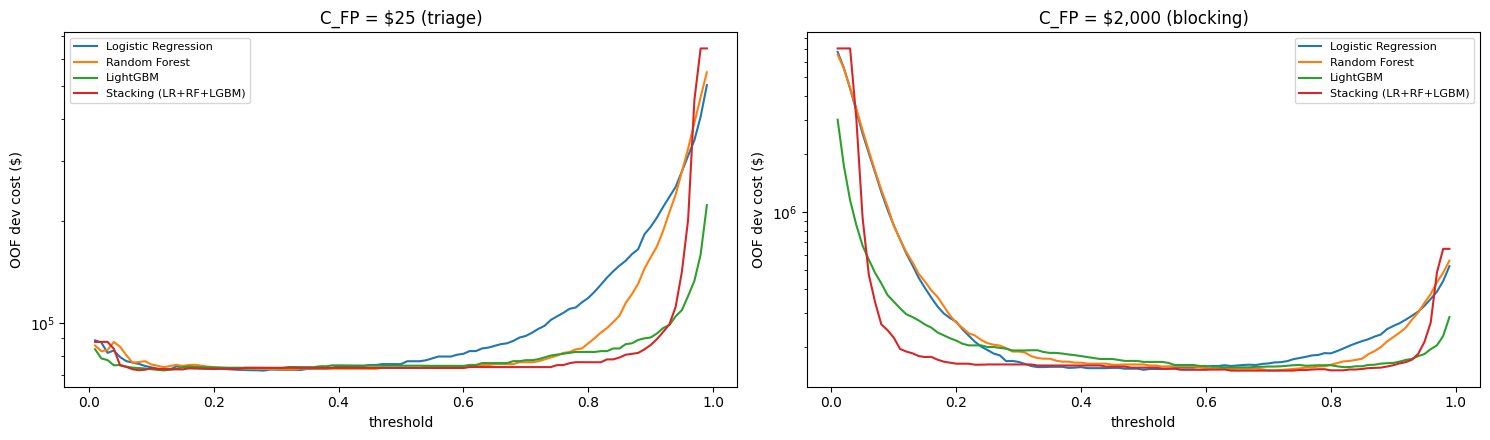

[Logistic Regression] frozen threshold = 0.28 ; thresholds within 2% of the minimal OOF cost: 0.11 to 0.39  -> very flat cost curve
Theoretical threshold if probabilities were calibrated: C_FP/(C_FP+C_FN) = 0.048 (triage) ; 0.800 (blocking)
Test false negatives: 34 ; median LR p = 0.031 ; share with p < 0.10 = 97% (confident FNs: consistent with label noise, not proven)
TPR = 0.894, FPR = 0.0114


,prevalence,alerts/day,precision
0,0.005,189.655,0.283
1,0.010,242.637,0.442
2,0.020,348.599,0.616
3,0.050,666.487,0.805
4,0.268,2980.000,0.966


In [14]:
COST_FP, COST_FN = 25, 500
GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)

def conf(y_true, p, t):
    pred = p >= t
    tp = int(((pred) & (y_true == 1)).sum()); fp = int(((pred) & (y_true == 0)).sum())
    fn = int(((~pred) & (y_true == 1)).sum()); tn = int(((~pred) & (y_true == 0)).sum())
    return tp, fp, fn, tn

def cost_curve(y_true, p, cfp, cfn):
    return np.array([cfp * conf(y_true, p, t)[1] + cfn * conf(y_true, p, t)[2] for t in GRID])

def best_threshold(cc):
    idx = np.where(cc == cc.min())[0]; return GRID[idx[len(idx) // 2]]    # middle of the plateau of minima

# Out-of-fold probabilities on DEV (same folds as the benchmark)
oof = {n: cross_val_predict(models[n], X_dev, y_dev, cv=skf, method="predict_proba")[:, 1] for n in SHORTLIST}

def run_scenario(cfp, cfn=COST_FN):
    rows = []
    for n in SHORTLIST:
        cc = cost_curve(y_dev.values, oof[n], cfp, cfn); t = best_threshold(cc)      # chosen on OOF only
        tp, fp, fn, tn = conf(yt, proba[n], t)                                        # evaluated ONCE on the test set
        rows.append({"Model": n, "Frozen threshold": t, "OOF dev cost": cc.min(), "TP": tp, "FP": fp, "FN": fn,
                     "Precision": tp / max(tp + fp, 1), "Recall": tp / (tp + fn),
                     "Test cost": cfp * fp + cfn * fn, "Test alerts": tp + fp,
                     "Alerts/day (indicative)": (tp + fp) / len(yt) * 12000})
    return pd.DataFrame(rows).set_index("Model").round(3)

print(f"=== Analyst-triage scenario: C_FP={COST_FP}, C_FN={COST_FN} ===")
res_triage = run_scenario(COST_FP); display(res_triage)
print("=== Inline-blocking scenario: C_FP=2000, C_FN=500 ===")
res_block = run_scenario(2000); display(res_block)
print(f"Test references: flag nothing = ${COST_FN*int(yt.sum())} ; flag everything = ${COST_FP*int((yt==0).sum())} (triage)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, cfp, ttl in [(ax[0], COST_FP, "C_FP = $25 (triage)"), (ax[1], 2000, "C_FP = $2,000 (blocking)")]:
    for n in SHORTLIST:
        a.plot(GRID, cost_curve(y_dev.values, oof[n], cfp, COST_FN), label=n)
    a.set(xlabel="threshold", ylabel="OOF dev cost ($)", title=ttl, yscale="log"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# --- Additional diagnostics (recommended model: logistic regression, frozen triage threshold) ---
REC = "Logistic Regression"; t_rec = res_triage.loc[REC, "Frozen threshold"]
cc = cost_curve(y_dev.values, oof[REC], COST_FP, COST_FN)
near = GRID[cc <= 1.02 * cc.min()]
print(f"[{REC}] frozen threshold = {t_rec} ; thresholds within 2% of the minimal OOF cost: {near.min()} to {near.max()}  -> very flat cost curve")
print(f"Theoretical threshold if probabilities were calibrated: C_FP/(C_FP+C_FN) = {COST_FP/(COST_FP+COST_FN):.3f} (triage) ; {2000/(2000+COST_FN):.3f} (blocking)")
fn_mask = (yt == 1) & (proba[REC] < t_rec)
print(f"Test false negatives: {fn_mask.sum()} ; median LR p = {np.median(proba[REC][fn_mask]):.3f} ; "
      f"share with p < 0.10 = {(proba[REC][fn_mask] < 0.10).mean():.0%} (confident FNs: consistent with label noise, not proven)")

# Prevalence sensitivity: frozen test TPR/FPR applied to other prevalences (indicative, assumes constant TPR/FPR)
tp, fp, fn, tn = conf(yt, proba[REC], t_rec); tpr, fpr = tp / (tp + fn), fp / (fp + tn)
sh = pd.DataFrame({"prevalence": [0.005, 0.01, 0.02, 0.05, float(yt.mean())]})
sh["alerts/day"] = 12000 * (tpr * sh["prevalence"] + fpr * (1 - sh["prevalence"]))
sh["precision"] = tpr * sh["prevalence"] / (tpr * sh["prevalence"] + fpr * (1 - sh["prevalence"]))
print(f"TPR = {tpr:.3f}, FPR = {fpr:.4f}"); display(sh.round(3))

### Cost/threshold analysis — reading
Thresholds are chosen on **development out-of-fold probabilities only**, frozen, then evaluated **once** on the test set (no threshold search on the test set).

**Triage (C_FP = \$25, C_FN = \$500)** — frozen thresholds: LR 0.28; RF 0.33; LightGBM 0.12; Stacking 0.08. On the test set: cost \$17,250 (LR), \$17,300 (RF), \$17,650 (LightGBM), \$16,975 (Stacking), with recall ≈ 0.89–0.90 and precision 0.92–0.97. Differences between models (≤ 4 %) are noise on 1,200 files (~322 malware). References: flag nothing = \$161,000; flag everything = \$21,950. The model therefore cuts cost by ~89 % vs "nothing", but only ~21 % vs "flag everything": with FP = \$25 and 27 % malware, flagging everything is a surprisingly competitive alternative.

**Inline blocking (C_FP = \$2,000)** — higher frozen thresholds: LR 0.50; RF 0.71; LightGBM 0.65; Stacking 0.69. Test cost rises to ~\$34,000–36,000: just 8 FPs cost \$16,000. The threshold rises because an FP now costs 4× an FN (the theoretical threshold of a calibrated model moves from C_FP/(C_FP+C_FN) = 0.048 to 0.80). Observed thresholds are less extreme than these theoretical values, probably because scores are well separated and the cost curve is **very flat**: for LR, any threshold between 0.11 and 0.39 costs ≤ 2 % more than the minimum — the threshold is not tightly identified.

**Remaining false negatives**: 34 FNs for LR, 97 % of them with p < 0.10: these malware samples look benign to the model, consistent with noisy labels (not proven) — a lower threshold does not recover them.

**Capacity (indicative)**: ~298 alerts on 1,200 files → ~**2,980 alerts/day** extrapolated to 12,000 files, ~25× the 120 target. The gap comes from the synthetic prevalence (26.8 % ≈ 3,200 malware/day) and is not a forecast. Sensitivity test (TPR = 0.894 and FPR = 0.0114 frozen, constant-rate assumption): at 0.5 % prevalence ≈ 190 alerts/day (precision 0.28); at 1 % ≈ 243 (0.44); at 2 % ≈ 349 (0.62). **The 120 target is not met at any plausible prevalence at this threshold**, since the FPR alone would already produce ~137 false alerts/day. An FPR below ~1 % would be needed (higher threshold, lower recall).

**Limitations**: illustrative costs (heterogeneous in reality: an FN on a payment workstation ≠ a generic FN); synthetic prevalence not representative; uncalibrated scores; noisy labels; a 1,200-file test set, hence wide intervals; synthetic distributions, no drift and no adversary. Real telemetry, calibration (Platt/isotonic) and a threshold expressed as alert capacity would be needed.

## Phase 5 — Final architecture decision: CISO recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?
2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?
3. What threshold do you recommend under the supplied cost assumptions?
4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?
5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?
6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?


**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.

## ✅ Recommendation to the CISO (results of this run, seed 42)

1. Business use case and deployment strategy
AtlasPay wants to use Machine Learning to detect malicious network traffic and suspicious activities. The positive class (1) represents malicious traffic, while class (0) represents normal traffic. The initial deployment should be analyst-assisted because false positives could affect legitimate users. Security analysts must review alerts before taking action.
2. Recommended model
I recommend the Stacking model for perimeter scanning because it achieved the best PR-AUC (0.9090) and validation F1-score (0.9244) among the tested models.
3. Recommended threshold
I recommend a threshold of 0.08 because missing a real attack (FN = $500) is much more expensive than generating a false alert (fp = $25).
4. Supporting evidence
For stacking: 0.898 and 0.938 (PR-AUC: 0.9090 / $16,975 cost) = 19 FPs and 33 FNs. It also achieved the validation mark of 0.9244 F1-score. Latency and explainability measurements are still needed.
5. Alert volume and inline blocking
We cannot confirm if the system respects the 120-alert/day target because we do not know the test duration or daily traffic volume. We need real daily traffic data to calculate the alert rate. For inline blocking, I recommend a higher and carefully tested threshold because false positives could interrupt legitimate payment-support operations.
6. Main risks before production
The main risks are the difference between synthetic and real data, incorrect labels, changes in attack frequency, data drift, poor probability calibration, attackers adapting their techniques, too many alerts for analysts and insufficient model monitoring. These risks must be tested before production deployment.